# Dia 20 — `argparse` e scripts de linha de comando (CLI) para Data Science

**Fase 1 — Fundamentos de Python · Dia 20 de 28 · 19/11/2026**

Até aqui, quase tudo foi feito *dentro* de notebooks. Em produção, porém, pipelines de dados costumam rodar como **scripts** chamados por agendadores (cron, Airflow), por CI/CD ou por colegas no terminal. A ponte entre "código que funciona no notebook" e "ferramenta reutilizável" é uma boa **interface de linha de comando**.

Neste notebook:

1. **Introdução ao `argparse`** — argumentos posicionais, opcionais, *flags*, tipos, padrões e mensagens de ajuda.
2. **Recursos avançados** — subcomandos, grupos, grupos mutuamente exclusivos, *actions* personalizadas e validação.
3. **CLI de pipeline de DS** — `train` / `evaluate` / `predict` com datasets reais do scikit-learn, executado via `subprocess`.
4. **Aplicação em NLP/educação** — CLI de análise de vocabulário sobre o Brown Corpus (NLTK), com faixas de frequência *inspiradas* no CEFR.
5. **Boas práticas** — `nbconvert`, `argparse` + `logging`, testes com `pytest` e *entry points*.

> **Dados:** apenas datasets públicos reais — `seaborn.load_dataset` (iris, tips, titanic), `sklearn.datasets` (iris, wine, breast_cancer) e o Brown Corpus do NLTK. Nenhum dado sintético.

In [1]:
"""Shared imports and a temporary working directory for the CLI scripts."""
import argparse
import json
import subprocess
import sys
import tempfile
import textwrap
from pathlib import Path

import pandas as pd
import seaborn as sns

WORKDIR = Path(tempfile.mkdtemp(prefix="day20_cli_"))
PY = sys.executable  # use the same interpreter that runs this kernel

print(f"Python: {sys.version.split()[0]}")
print(f"argparse is part of the standard library: {argparse.__name__}")
print(f"Scripts will be written to a temporary folder: {WORKDIR.name}")

Python: 3.11.17
argparse is part of the standard library: argparse
Scripts will be written to a temporary folder: day20_cli_87rv5go8


## 1. Introdução ao `argparse`

O `argparse` (biblioteca padrão) transforma a lista `sys.argv` em um objeto `Namespace` com atributos tipados. Ele oferece de graça:

- **validação** de tipos e de escolhas (`choices`);
- **mensagens de ajuda** (`-h/--help`) geradas automaticamente;
- **códigos de saída** padronizados (`2` para erro de uso).

Três tipos de argumento:

| Tipo | Exemplo | Uso típico em DS |
|---|---|---|
| Posicional | `dataset` | entrada obrigatória (nome do dataset, caminho do arquivo) |
| Opcional | `--n-rows 10` | parâmetros com valor padrão (amostra, semente) |
| *Flag* | `--verbose` | liga/desliga comportamento (`store_true`) |

**Dica de notebook:** dentro do Jupyter, `sys.argv` contém argumentos do kernel. Por isso passamos uma lista explícita para `parser.parse_args([...])`.

In [2]:
def build_basic_parser() -> argparse.ArgumentParser:
    """Create a parser with one positional, two optionals and one flag."""
    parser = argparse.ArgumentParser(
        prog="summarize",
        description="Print summary statistics for a seaborn dataset.",
    )
    parser.add_argument("dataset", help="seaborn dataset name, e.g. 'iris'")
    parser.add_argument("--n-rows", type=int, default=5,
                        help="number of rows to preview (default: %(default)s)")
    parser.add_argument("--columns", nargs="+", default=None,
                        help="optional subset of columns")
    parser.add_argument("-v", "--verbose", action="store_true",
                        help="print extra information")
    return parser


basic_parser = build_basic_parser()
args = basic_parser.parse_args(["iris", "--n-rows", "3", "--verbose"])
print(args)
print(type(args.n_rows), "<- string '3' converted to int; dashes become underscores")

Namespace(dataset='iris', n_rows=3, columns=None, verbose=True)
<class 'int'> <- string '3' converted to int; dashes become underscores


In [3]:
# The auto-generated help text is documentation that never goes out of date.
basic_parser.print_help()

usage: summarize [-h] [--n-rows N_ROWS] [--columns COLUMNS [COLUMNS ...]] [-v]
                 dataset

Print summary statistics for a seaborn dataset.

positional arguments:
  dataset               seaborn dataset name, e.g. 'iris'

options:
  -h, --help            show this help message and exit
  --n-rows N_ROWS       number of rows to preview (default: 5)
  --columns COLUMNS [COLUMNS ...]
                        optional subset of columns
  -v, --verbose         print extra information


### Conversão de tipos, valores padrão e `choices`

O parâmetro `type` aceita **qualquer função** que receba uma string — `int`, `float`, `Path` ou uma função própria. `choices` restringe os valores aceitos e aparece no `--help`. Abaixo, um parser que lê um dataset real do seaborn e imprime estatísticas descritivas.

In [4]:
def run_summary(argv: list[str]) -> pd.DataFrame:
    """Parse argv, load a real seaborn dataset and return its describe() table."""
    parser = argparse.ArgumentParser(prog="summarize")
    parser.add_argument("dataset", choices=["iris", "tips", "titanic"])
    parser.add_argument("--n-rows", type=int, default=5)
    parser.add_argument("--quantile", type=float, default=0.5,
                        help="extra quantile to report")
    parser.add_argument("--numeric-only", action="store_true")
    args = parser.parse_args(argv)

    df = sns.load_dataset(args.dataset)
    print(f"{args.dataset}: {df.shape[0]} rows x {df.shape[1]} columns")
    print(df.head(args.n_rows).to_string(), "\n")
    summary = df.describe() if args.numeric_only else df.describe(include="all")
    numeric = df.select_dtypes("number")
    summary.loc[f"q{args.quantile:.2f}", numeric.columns] = numeric.quantile(args.quantile)
    return summary


run_summary(["tips", "--n-rows", "3", "--quantile", "0.9", "--numeric-only"]).round(2)

tips: 244 rows x 7 columns
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3 



,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00
q0.90,32.24,5.00,4.00


In [5]:
# Invalid input -> argparse prints a usage message and raises SystemExit(2).
try:
    run_summary(["penguins"])           # not in choices
except SystemExit as exc:
    print(f"\nSystemExit code: {exc.code}")


SystemExit code: 2


usage: summarize [-h] [--n-rows N_ROWS] [--quantile QUANTILE] [--numeric-only]
                 {iris,tips,titanic}
summarize: error: argument dataset: invalid choice: 'penguins' (choose from 'iris', 'tips', 'titanic')


## 2. Recursos avançados do `argparse`

Ferramentas reais (`git`, `pip`, `dvc`) usam **subcomandos**: `git commit`, `pip install`. No `argparse` isso é feito com `add_subparsers()`. Cada subcomando tem seus próprios argumentos, e `set_defaults(func=...)` associa uma função a ele — o padrão de *dispatch* mais limpo.

Também veremos:

- `add_argument_group()` — organiza o `--help` em seções;
- `add_mutually_exclusive_group()` — impede combinações sem sentido (ex.: `--csv` **e** `--json`);
- `argparse.Action` personalizada — lógica própria ao ler um argumento;
- validadores de tipo — mensagens de erro claras com `ArgumentTypeError`.

In [6]:
def positive_int(value: str) -> int:
    """argparse type: accept only strictly positive integers."""
    try:
        number = int(value)
    except ValueError:
        raise argparse.ArgumentTypeError(f"{value!r} is not an integer")
    if number <= 0:
        raise argparse.ArgumentTypeError(f"{value} must be > 0")
    return number


def fraction(value: str) -> float:
    """argparse type: accept floats in the open interval (0, 1)."""
    number = float(value)
    if not 0 < number < 1:
        raise argparse.ArgumentTypeError(f"{value} must be between 0 and 1 (exclusive)")
    return number


class ColumnListAction(argparse.Action):
    """Custom action: split 'a,b,c' into ['a', 'b', 'c'] and strip whitespace."""

    def __call__(self, parser, namespace, values, option_string=None):
        columns = [c.strip() for c in values.split(",") if c.strip()]
        if not columns:
            parser.error(f"{option_string} needs at least one column name")
        setattr(namespace, self.dest, columns)


demo = argparse.ArgumentParser(prog="demo")
demo.add_argument("--top", type=positive_int, default=5)
demo.add_argument("--test-size", type=fraction, default=0.25)
demo.add_argument("--cols", action=ColumnListAction, default=None)
print(demo.parse_args(["--top", "10", "--test-size", "0.3", "--cols", "sex, age ,fare"]))

for bad in (["--top", "0"], ["--test-size", "1.5"], ["--cols", " , "]):
    try:
        demo.parse_args(bad)
    except SystemExit as exc:
        print(f"   -> rejected {bad} (exit code {exc.code})")

Namespace(top=10, test_size=0.3, cols=['sex', 'age', 'fare'])
   -> rejected ['--top', '0'] (exit code 2)
   -> rejected ['--test-size', '1.5'] (exit code 2)
   -> rejected ['--cols', ' , '] (exit code 2)


usage: demo [-h] [--top TOP] [--test-size TEST_SIZE] [--cols COLS]
demo: error: argument --top: 0 must be > 0
usage: demo [-h] [--top TOP] [--test-size TEST_SIZE] [--cols COLS]
demo: error: argument --test-size: 1.5 must be between 0 and 1 (exclusive)
usage: demo [-h] [--top TOP] [--test-size TEST_SIZE] [--cols COLS]
demo: error: --cols needs at least one column name


### Uma CLI com subcomandos: `analyze`, `visualize`, `export`

A função `build_ds_tool()` abaixo monta uma ferramenta com três subcomandos sobre os datasets do seaborn. Repare:

- `required=True` em `add_subparsers` obriga o usuário a escolher um subcomando;
- um **parser pai** (`parents=[common]`) evita repetir `--dataset` em todos os subcomandos;
- `export` usa um **grupo mutuamente exclusivo** para o formato de saída.

In [7]:
import matplotlib
matplotlib.use("Agg")  # headless backend: safe for scripts and CI
import matplotlib.pyplot as plt


def cmd_analyze(args: argparse.Namespace) -> dict:
    """Group-by analysis of a numeric column."""
    df = sns.load_dataset(args.dataset)
    result = df.groupby(args.by, observed=True)[args.column].agg(["count", "mean", "std"]).round(3)
    print(result.to_string())
    return {"rows": len(df), "groups": len(result)}


def cmd_visualize(args: argparse.Namespace) -> dict:
    """Save a histogram of one column to a PNG file."""
    df = sns.load_dataset(args.dataset)
    fig, ax = plt.subplots(figsize=(5, 3))
    sns.histplot(data=df, x=args.column, bins=args.bins, ax=ax)
    ax.set_title(f"{args.dataset}: {args.column}")
    out = WORKDIR / f"{args.dataset}_{args.column}.png"
    fig.savefig(out, dpi=80, bbox_inches="tight")
    plt.close(fig)
    print(f"saved {out.name} ({out.stat().st_size} bytes)")
    return {"figure": out.name}


def cmd_export(args: argparse.Namespace) -> dict:
    """Export the first N rows as CSV or JSON."""
    df = sns.load_dataset(args.dataset).head(args.limit)
    suffix = "json" if args.json else "csv"
    out = WORKDIR / f"{args.dataset}.{suffix}"
    df.to_json(out, orient="records") if args.json else df.to_csv(out, index=False)
    print(f"exported {len(df)} rows to {out.name}")
    return {"file": out.name}


def build_ds_tool() -> argparse.ArgumentParser:
    """Assemble the multi-command parser."""
    common = argparse.ArgumentParser(add_help=False)
    common.add_argument("--dataset", choices=["iris", "tips", "titanic"], default="tips")

    parser = argparse.ArgumentParser(prog="dstool", description="Small DS toolbox.")
    sub = parser.add_subparsers(dest="command", required=True, metavar="COMMAND")

    p_an = sub.add_parser("analyze", parents=[common], help="group-by statistics")
    p_an.add_argument("--by", required=True)
    p_an.add_argument("--column", required=True)
    p_an.set_defaults(func=cmd_analyze)

    p_vis = sub.add_parser("visualize", parents=[common], help="histogram to PNG")
    p_vis.add_argument("--column", required=True)
    p_vis.add_argument("--bins", type=positive_int, default=20)
    p_vis.set_defaults(func=cmd_visualize)

    p_ex = sub.add_parser("export", parents=[common], help="export rows")
    p_ex.add_argument("--limit", type=positive_int, default=10)
    fmt = p_ex.add_mutually_exclusive_group()
    fmt.add_argument("--csv", action="store_true", help="CSV output (default)")
    fmt.add_argument("--json", action="store_true", help="JSON output")
    p_ex.set_defaults(func=cmd_export)
    return parser


dstool = build_ds_tool()
dstool.print_help()

usage: dstool [-h] COMMAND ...

Small DS toolbox.

positional arguments:
  COMMAND
    analyze   group-by statistics
    visualize
              histogram to PNG
    export    export rows

options:
  -h, --help  show this help message and exit


In [8]:
def dispatch(argv: list[str]) -> dict:
    """Parse argv and call the function attached to the chosen subcommand."""
    args = dstool.parse_args(argv)
    return args.func(args)


print(dispatch(["analyze", "--dataset", "tips", "--by", "day", "--column", "total_bill"]), "\n")
print(dispatch(["visualize", "--dataset", "iris", "--column", "petal_length", "--bins", "15"]), "\n")
print(dispatch(["export", "--dataset", "titanic", "--limit", "5", "--json"]))

      count    mean    std
day                       
Thur     62  17.683  7.886
Fri      19  17.152  8.303
Sat      87  20.441  9.480
Sun      76  21.410  8.832
{'rows': 244, 'groups': 4} 

saved iris_petal_length.png (9202 bytes)
{'figure': 'iris_petal_length.png'} 

exported 5 rows to titanic.json
{'file': 'titanic.json'}


In [9]:
# Mutually exclusive group in action: --csv and --json together are rejected.
try:
    dispatch(["export", "--csv", "--json"])
except SystemExit as exc:
    print(f"exit code {exc.code}")

# Argument groups only change how --help is organized.
grouped = argparse.ArgumentParser(prog="grouped")
io = grouped.add_argument_group("input/output")
io.add_argument("--input", type=Path)
io.add_argument("--output", type=Path)
model = grouped.add_argument_group("model hyperparameters")
model.add_argument("--max-depth", type=positive_int, default=3)
model.add_argument("--learning-rate", type=float, default=0.1)
grouped.print_help()

exit code 2
usage: grouped [-h] [--input INPUT] [--output OUTPUT] [--max-depth MAX_DEPTH]
               [--learning-rate LEARNING_RATE]

options:
  -h, --help            show this help message and exit

input/output:
  --input INPUT
  --output OUTPUT

model hyperparameters:
  --max-depth MAX_DEPTH
  --learning-rate LEARNING_RATE


usage: dstool export [-h] [--dataset {iris,tips,titanic}] [--limit LIMIT]
                     [--csv | --json]
dstool export: error: argument --json: not allowed with argument --csv


### Validação além do parser

Alguns erros só podem ser detectados **depois** de carregar os dados (ex.: a coluna pedida existe?). Nesses casos, use `parser.error(msg)`: ele imprime o uso, a mensagem e sai com código `2` — consistente com os demais erros de uso. Erros de **execução** (arquivo corrompido, modelo falhou) devem usar outro código (ex.: `1`).

In [10]:
def validated_analyze(argv: list[str]) -> None:
    """Parse args, then validate them against the real data columns."""
    args = dstool.parse_args(argv)
    df = sns.load_dataset(args.dataset)
    missing = [c for c in (args.by, args.column) if c not in df.columns]
    if missing:
        dstool.error(f"column(s) {missing} not found in {args.dataset}; "
                     f"available: {list(df.columns)}")
    if not pd.api.types.is_numeric_dtype(df[args.column]):
        dstool.error(f"--column {args.column!r} must be numeric")
    args.func(args)


try:
    validated_analyze(["analyze", "--dataset", "titanic", "--by", "class", "--column", "salary"])
except SystemExit as exc:
    print(f"exit code {exc.code}")
print()
validated_analyze(["analyze", "--dataset", "titanic", "--by", "class", "--column", "fare"])

exit code 2

        count    mean     std
class                        
First     216  84.155  78.380
Second    184  20.662  13.417
Third     491  13.676  11.778


usage: dstool [-h] COMMAND ...
dstool: error: column(s) ['salary'] not found in titanic; available: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


## 3. Construindo uma CLI de pipeline de Data Science

Agora vamos escrever um **script de verdade** (`ds_pipeline.py`) em disco e executá-lo como um processo separado — exatamente como seria rodado por um agendador.

Desenho da interface:

```
python ds_pipeline.py [--verbose] train    --dataset {iris,wine,breast_cancer} --model {logreg,rf,knn} --output model.joblib
python ds_pipeline.py [--verbose] evaluate --model-path model.joblib --output metrics.json
python ds_pipeline.py [--verbose] predict  --model-path model.joblib --n-samples 5 --output preds.csv
```

Decisões de projeto:

- **`main(argv=None)`**: permite testar o script chamando `main([...])` sem `subprocess`;
- **split determinístico** (`--test-size`, `--seed`) salvo junto com o modelo, para que `evaluate` use exatamente o mesmo conjunto de teste;
- **saídas legíveis por máquina** (JSON/CSV) + **códigos de saída** (`0` sucesso, `1` erro de execução, `2` erro de uso).

In [11]:
PIPELINE_SRC = textwrap.dedent('''
    """ds_pipeline.py - train / evaluate / predict CLI for sklearn toy datasets."""
    import argparse
    import json
    import logging
    import sys
    from pathlib import Path

    import joblib
    import pandas as pd
    from sklearn.datasets import load_breast_cancer, load_iris, load_wine
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import accuracy_score, classification_report, f1_score
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    LOADERS = {"iris": load_iris, "wine": load_wine, "breast_cancer": load_breast_cancer}
    MODELS = {
        "logreg": lambda seed: LogisticRegression(max_iter=5000, random_state=seed),
        "rf": lambda seed: RandomForestClassifier(n_estimators=200, random_state=seed),
        "knn": lambda seed: KNeighborsClassifier(n_neighbors=5),
    }
    log = logging.getLogger("ds_pipeline")


    def load_split(name, test_size, seed):
        """Load a real sklearn dataset and return a stratified train/test split."""
        bunch = LOADERS[name](as_frame=True)
        X, y = bunch.data, bunch.target
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=test_size, random_state=seed, stratify=y)
        return X_tr, X_te, y_tr, y_te, list(bunch.target_names)


    def cmd_train(args):
        """Fit a scaled classifier and persist it with its split metadata."""
        X_tr, X_te, y_tr, y_te, names = load_split(args.dataset, args.test_size, args.seed)
        log.info("dataset=%s train=%d test=%d features=%d",
                 args.dataset, len(X_tr), len(X_te), X_tr.shape[1])
        pipe = make_pipeline(StandardScaler(), MODELS[args.model](args.seed)).fit(X_tr, y_tr)
        bundle = {"pipeline": pipe, "dataset": args.dataset, "model": args.model,
                  "test_size": args.test_size, "seed": args.seed, "target_names": names}
        joblib.dump(bundle, args.output)
        print(json.dumps({"status": "trained", "model": args.model,
                          "dataset": args.dataset, "train_accuracy":
                          round(pipe.score(X_tr, y_tr), 4), "output": str(args.output)}))
        return 0


    def cmd_evaluate(args):
        """Score a saved model on the exact held-out split used at training time."""
        bundle = joblib.load(args.model_path)
        _, X_te, _, y_te, names = load_split(bundle["dataset"], bundle["test_size"], bundle["seed"])
        pred = bundle["pipeline"].predict(X_te)
        metrics = {"dataset": bundle["dataset"], "model": bundle["model"],
                   "n_test": int(len(y_te)),
                   "accuracy": round(accuracy_score(y_te, pred), 4),
                   "f1_macro": round(f1_score(y_te, pred, average="macro"), 4)}
        log.info("\\n%s", classification_report(y_te, pred, target_names=names))
        text = json.dumps(metrics, indent=2)
        if args.output:
            Path(args.output).write_text(text)
        print(text)
        return 0


    def cmd_predict(args):
        """Predict the first N held-out rows and write CSV (or stdout)."""
        bundle = joblib.load(args.model_path)
        _, X_te, _, y_te, names = load_split(bundle["dataset"], bundle["test_size"], bundle["seed"])
        X_new = X_te.head(args.n_samples)
        proba = bundle["pipeline"].predict_proba(X_new).max(axis=1)
        out = pd.DataFrame({"row_id": X_new.index,
                            "true": [names[i] for i in y_te.head(args.n_samples)],
                            "predicted": [names[i] for i in bundle["pipeline"].predict(X_new)],
                            "confidence": proba.round(3)})
        if args.output:
            out.to_csv(args.output, index=False)
            log.info("wrote %d predictions to %s", len(out), args.output)
        print(out.to_string(index=False))
        return 0


    def build_parser():
        """Define the CLI: global --verbose plus three subcommands."""
        parser = argparse.ArgumentParser(prog="ds_pipeline",
                                         description="Train/evaluate/predict sklearn models.")
        parser.add_argument("-v", "--verbose", action="count", default=0,
                            help="-v for INFO, -vv for DEBUG")
        sub = parser.add_subparsers(dest="command", required=True)

        tr = sub.add_parser("train", help="fit and save a model")
        tr.add_argument("--dataset", choices=sorted(LOADERS), required=True)
        tr.add_argument("--target", default="target",
                        help="target column (sklearn bunches expose it as 'target')")
        tr.add_argument("--model", choices=sorted(MODELS), default="logreg")
        tr.add_argument("--test-size", type=float, default=0.25)
        tr.add_argument("--seed", type=int, default=42)
        tr.add_argument("--output", type=Path, required=True)
        tr.set_defaults(func=cmd_train)

        ev = sub.add_parser("evaluate", help="score a saved model")
        ev.add_argument("--model-path", type=Path, required=True)
        ev.add_argument("--output", type=Path, help="optional JSON metrics file")
        ev.set_defaults(func=cmd_evaluate)

        pr = sub.add_parser("predict", help="predict held-out rows")
        pr.add_argument("--model-path", type=Path, required=True)
        pr.add_argument("--n-samples", type=int, default=5)
        pr.add_argument("--output", type=Path, help="optional CSV file")
        pr.set_defaults(func=cmd_predict)
        return parser


    def main(argv=None):
        """Entry point; returns a process exit code."""
        parser = build_parser()
        args = parser.parse_args(argv)
        if getattr(args, "target", "target") != "target":
            parser.error("sklearn toy datasets only expose the column 'target'")
        level = [logging.WARNING, logging.INFO, logging.DEBUG][min(args.verbose, 2)]
        logging.basicConfig(level=level, stream=sys.stderr,
                            format="%(levelname)s %(name)s: %(message)s")
        try:
            return args.func(args)
        except FileNotFoundError as exc:
            log.error("file not found: %s", exc.filename)
            return 1


    if __name__ == "__main__":
        sys.exit(main())
''')

pipeline_path = WORKDIR / "ds_pipeline.py"
pipeline_path.write_text(PIPELINE_SRC)
print(f"wrote {pipeline_path.name}: {len(PIPELINE_SRC.splitlines())} lines")

wrote ds_pipeline.py: 135 lines


### Chamando o script a partir do notebook com `subprocess`

`subprocess.run([...])` executa o script em um processo novo. Boas práticas:

- passar a **lista** de argumentos (nunca `shell=True` com strings montadas — risco de injeção);
- usar `sys.executable` para garantir o mesmo ambiente Python;
- `capture_output=True, text=True` para inspecionar `stdout`, `stderr` e `returncode`.

Vamos encapsular isso em uma função auxiliar.

In [12]:
def run_cli(*cli_args: str, show_stderr: bool = False) -> subprocess.CompletedProcess:
    """Run ds_pipeline.py in a subprocess and print its output."""
    cmd = [PY, str(pipeline_path), *cli_args]
    result = subprocess.run(cmd, capture_output=True, text=True, cwd=WORKDIR, timeout=120)
    print(f"$ python ds_pipeline.py {' '.join(cli_args)}   -> exit {result.returncode}")
    if result.stdout:
        print(result.stdout.rstrip())
    if show_stderr and result.stderr:
        print("[stderr]\n" + result.stderr.rstrip())
    return result


_ = run_cli("--help")

$ python ds_pipeline.py --help   -> exit 0
usage: ds_pipeline [-h] [-v] {train,evaluate,predict} ...

Train/evaluate/predict sklearn models.

positional arguments:
  {train,evaluate,predict}
    train               fit and save a model
    evaluate            score a saved model
    predict             predict held-out rows

options:
  -h, --help            show this help message and exit
  -v, --verbose         -v for INFO, -vv for DEBUG


In [13]:
# Train: logistic regression on the real Wine dataset (178 samples, 13 features).
res = run_cli("train", "--dataset", "wine", "--model", "logreg", "--output", "wine_logreg.joblib")
train_info = json.loads(res.stdout)
train_info

$ python ds_pipeline.py train --dataset wine --model logreg --output wine_logreg.joblib   -> exit 0
{"status": "trained", "model": "logreg", "dataset": "wine", "train_accuracy": 1.0, "output": "wine_logreg.joblib"}


{'status': 'trained',
 'model': 'logreg',
 'dataset': 'wine',
 'train_accuracy': 1.0,
 'output': 'wine_logreg.joblib'}

In [14]:
# Evaluate with -v so INFO logs (including the classification report) go to stderr.
res = run_cli("-v", "evaluate", "--model-path", "wine_logreg.joblib",
              "--output", "wine_metrics.json", show_stderr=True)

$ python ds_pipeline.py -v evaluate --model-path wine_logreg.joblib --output wine_metrics.json   -> exit 0
{
  "dataset": "wine",
  "model": "logreg",
  "n_test": 45,
  "accuracy": 1.0,
  "f1_macro": 1.0
}
[stderr]
INFO ds_pipeline: 
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45


In [15]:
# Predict: write a CSV that downstream tools can consume.
res = run_cli("predict", "--model-path", "wine_logreg.joblib", "--n-samples", "6",
              "--output", "wine_preds.csv")
pd.read_csv(WORKDIR / "wine_preds.csv")

$ python ds_pipeline.py predict --model-path wine_logreg.joblib --n-samples 6 --output wine_preds.csv   -> exit 0
 row_id    true predicted  confidence
     35 class_0   class_0       0.926
     93 class_1   class_1       0.996
      7 class_0   class_0       0.999
     28 class_0   class_0       0.990
     87 class_1   class_1       0.999
     42 class_0   class_0       1.000


,row_id,true,predicted,confidence
0,35,class_0,class_0,0.926
1,93,class_1,class_1,0.996
2,7,class_0,class_0,0.999
3,28,class_0,class_0,0.990
4,87,class_1,class_1,0.999
5,42,class_0,class_0,1.000


### Um *grid* de experimentos orquestrado pela CLI

Como a CLI é determinística e devolve JSON, fica fácil orquestrá-la: abaixo treinamos e avaliamos **3 modelos × 3 datasets reais** (iris, wine, breast_cancer) e reunimos as métricas em um `DataFrame`. Esse é o mesmo padrão usado por um *shell script*, um `Makefile` ou um DAG do Airflow.

In [16]:
rows = []
for dataset in ["iris", "wine", "breast_cancer"]:
    for model in ["logreg", "rf", "knn"]:
        artifact = f"{dataset}_{model}.joblib"
        tr = subprocess.run([PY, str(pipeline_path), "train", "--dataset", dataset,
                             "--model", model, "--output", artifact],
                            capture_output=True, text=True, cwd=WORKDIR, check=True)
        ev = subprocess.run([PY, str(pipeline_path), "evaluate", "--model-path", artifact],
                            capture_output=True, text=True, cwd=WORKDIR, check=True)
        rows.append({**json.loads(ev.stdout),
                     "train_accuracy": json.loads(tr.stdout)["train_accuracy"]})

grid = pd.DataFrame(rows)
grid.pivot(index="dataset", columns="model", values="f1_macro")

model,knn,logreg,rf
dataset,,,
breast_cancer,0.9772,0.985,0.9547
iris,0.9220,0.923,0.9230
wine,0.9314,1.000,1.0000


**Leitura:** os valores acima são de **um único split** (25% teste, `seed=42`) — servem para demonstrar a orquestração, não para concluir qual modelo é "melhor". Para comparação séria usaríamos validação cruzada (tema da Fase 4).

### Erros de uso vs. erros de execução

Uma boa CLI comunica falhas pelo **código de saída**, para que o orquestrador saiba se deve parar o pipeline.

In [17]:
r1 = run_cli("train", "--dataset", "mnist", "--output", "x.joblib", show_stderr=True)  # usage error
print()
r2 = run_cli("evaluate", "--model-path", "does_not_exist.joblib", show_stderr=True)    # runtime error
print()
r3 = run_cli("train", "--dataset", "iris", "--target", "species", "--output", "x.joblib",
             show_stderr=True)                                                         # post-parse validation
assert (r1.returncode, r2.returncode, r3.returncode) == (2, 1, 2)

$ python ds_pipeline.py train --dataset mnist --output x.joblib   -> exit 2
[stderr]
usage: ds_pipeline train [-h] --dataset {breast_cancer,iris,wine}
                         [--target TARGET] [--model {knn,logreg,rf}]
                         [--test-size TEST_SIZE] [--seed SEED] --output OUTPUT
ds_pipeline train: error: argument --dataset: invalid choice: 'mnist' (choose from 'breast_cancer', 'iris', 'wine')



$ python ds_pipeline.py evaluate --model-path does_not_exist.joblib   -> exit 1
[stderr]
ERROR ds_pipeline: file not found: does_not_exist.joblib



$ python ds_pipeline.py train --dataset iris --target species --output x.joblib   -> exit 2
[stderr]
usage: ds_pipeline [-h] [-v] {train,evaluate,predict} ...
ds_pipeline: error: sklearn toy datasets only expose the column 'target'


In [18]:
# Because the script exposes main(argv), it can also be imported and called in-process -
# much faster for tests than spawning a subprocess.
import importlib.util

spec = importlib.util.spec_from_file_location("ds_pipeline", pipeline_path)
ds_pipeline = importlib.util.module_from_spec(spec)
spec.loader.exec_module(ds_pipeline)

exit_code = ds_pipeline.main(["train", "--dataset", "breast_cancer", "--model", "rf",
                              "--output", str(WORKDIR / "bc_rf.joblib")])
print("exit code:", exit_code)

{"status": "trained", "model": "rf", "dataset": "breast_cancer", "train_accuracy": 1.0, "output": "/tmp/day20_cli_87rv5go8/bc_rf.joblib"}
exit code: 0


## 4. Aplicação em NLP e ensino de inglês: CLI de análise de vocabulário

Para professores e pesquisadores de línguas, uma CLI permite analisar corpora **sem abrir um notebook**. Vamos criar `vocab_cli.py` com:

- `--corpus`: categoria(s) do **Brown Corpus** (NLTK) — ex.: `news`, `fiction`, `learned`;
- `--language`: idioma da lista de *stopwords* do NLTK;
- `--min-freq`: frequência mínima para entrar no relatório;
- `--output-format`: `table`, `json` ou `csv`;
- `--top`: quantas palavras listar.

**Ligação com o CEFR:** o script atribui a cada palavra uma **faixa de frequência** calculada no *Brown Corpus inteiro* (rank 1–1000 → "A1–A2-like", 1001–3000 → "B1–B2-like", acima → "C1+-like"). Isso é uma **heurística inspirada no CEFR**, comum em pesquisa sobre cobertura lexical — **não** são níveis CEFR oficiais (que dependem de listas como o English Vocabulary Profile).

In [19]:
VOCAB_SRC = textwrap.dedent('''
    """vocab_cli.py - vocabulary statistics for Brown Corpus categories."""
    import argparse
    import json
    import sys
    from collections import Counter
    from pathlib import Path

    from nltk.corpus import brown, stopwords

    BANDS = [(1000, "A1-A2-like"), (3000, "B1-B2-like"), (float("inf"), "C1+-like")]


    CACHE = Path(__file__).with_name("brown_ranks.json")


    def reference_ranks():
        """Frequency rank of each alphabetic lowercase word in the whole Brown Corpus.

        Ranks are cached next to the script so repeated runs stay fast.
        """
        if CACHE.exists():
            return json.loads(CACHE.read_text())
        counts = Counter(w.lower() for w in brown.words() if w.isalpha())
        ranks = {w: i for i, (w, _) in enumerate(counts.most_common(), start=1)}
        CACHE.write_text(json.dumps(ranks))
        return ranks


    def band_for(rank):
        """Map a reference frequency rank to a CEFR-inspired band label."""
        return next(label for limit, label in BANDS if rank <= limit)


    def analyze(categories, language, min_freq, top):
        """Compute frequency, vocabulary statistics and band coverage."""
        tokens = [w.lower() for w in brown.words(categories=categories) if w.isalpha()]
        stops = set(stopwords.words(language))
        content = [w for w in tokens if w not in stops]
        freq = Counter(content)
        ranks = reference_ranks()
        band_tokens = Counter(band_for(ranks[w]) for w in tokens)
        frequent = [(w, c) for w, c in freq.most_common() if c >= min_freq][:top]
        return {
            "corpus": categories,
            "tokens": len(tokens),
            "types": len(set(tokens)),
            "type_token_ratio": round(len(set(tokens)) / len(tokens), 4),
            "content_tokens": len(content),
            "hapax_legomena": sum(1 for c in freq.values() if c == 1),
            "types_with_min_freq": sum(1 for c in freq.values() if c >= min_freq),
            "band_coverage_pct": {b: round(100 * band_tokens[b] / len(tokens), 2)
                                  for _, b in BANDS},
            "top_words": [{"word": w, "freq": c, "band": band_for(ranks[w])}
                          for w, c in frequent],
        }


    def render(report, fmt):
        """Return the report as an aligned table, JSON or CSV string."""
        if fmt == "json":
            return json.dumps(report, indent=2)
        rows = report["top_words"]
        if fmt == "csv":
            return "word,freq,band\\n" + "\\n".join(
                f"{r['word']},{r['freq']},{r['band']}" for r in rows)
        head = [f"corpus={','.join(report['corpus'])} tokens={report['tokens']:,} "
                f"types={report['types']:,} TTR={report['type_token_ratio']}",
                f"coverage: {report['band_coverage_pct']}", "",
                f"{'word':<14}{'freq':>6}  band"]
        return "\\n".join(head + [f"{r['word']:<14}{r['freq']:>6}  {r['band']}" for r in rows])


    def build_parser():
        """CLI definition."""
        p = argparse.ArgumentParser(prog="vocab_cli",
                                    description="Vocabulary profile of Brown Corpus categories.")
        p.add_argument("--corpus", nargs="+", default=["news"], choices=brown.categories(),
                       metavar="CATEGORY", help="one or more Brown categories")
        p.add_argument("--language", default="english", choices=stopwords.fileids(),
                       metavar="LANG", help="NLTK stopword list (default: english)")
        p.add_argument("--min-freq", type=int, default=5)
        p.add_argument("--top", type=int, default=10)
        p.add_argument("--output-format", choices=["table", "json", "csv"], default="table")
        return p


    def main(argv=None):
        """Entry point returning an exit code."""
        args = build_parser().parse_args(argv)
        if args.min_freq < 1 or args.top < 1:
            build_parser().error("--min-freq and --top must be >= 1")
        print(render(analyze(args.corpus, args.language, args.min_freq, args.top),
                     args.output_format))
        return 0


    if __name__ == "__main__":
        sys.exit(main())
''')

vocab_path = WORKDIR / "vocab_cli.py"
vocab_path.write_text(VOCAB_SRC)


def run_vocab(*cli_args: str) -> subprocess.CompletedProcess:
    """Run vocab_cli.py and print stdout (and stderr when it fails)."""
    result = subprocess.run([PY, str(vocab_path), *cli_args],
                            capture_output=True, text=True, timeout=120)
    print(f"$ python vocab_cli.py {' '.join(cli_args)}   -> exit {result.returncode}")
    print(result.stdout.rstrip() or result.stderr.rstrip())
    return result


_ = run_vocab("--corpus", "news", "--top", "12")

$ python vocab_cli.py --corpus news --top 12   -> exit 0
corpus=news tokens=83,562 types=11,151 TTR=0.1334
coverage: {'A1-A2-like': 67.31, 'B1-B2-like': 13.08, 'C1+-like': 19.61}

word            freq  band
said             406  A1-A2-like
would            246  A1-A2-like
new              241  A1-A2-like
one              213  A1-A2-like
last             177  A1-A2-like
two              174  A1-A2-like
first            158  A1-A2-like
state            153  A1-A2-like
year             142  A1-A2-like
president        142  A1-A2-like
home             132  A1-A2-like
also             129  A1-A2-like


In [20]:
# Same tool, academic prose ("learned") and JSON output for further processing.
res = run_vocab("--corpus", "learned", "--min-freq", "20", "--top", "8", "--output-format", "json")
learned = json.loads(res.stdout)

$ python vocab_cli.py --corpus learned --min-freq 20 --top 8 --output-format json   -> exit 0
{
  "corpus": [
    "learned"
  ],
  "tokens": 157035,
  "types": 13510,
  "type_token_ratio": 0.086,
  "content_tokens": 83292,
  "hapax_legomena": 5756,
  "types_with_min_freq": 910,
  "band_coverage_pct": {
    "A1-A2-like": 68.95,
    "B1-B2-like": 13.19,
    "C1+-like": 17.86
  },
  "top_words": [
    {
      "word": "af",
      "freq": 908,
      "band": "A1-A2-like"
    },
    {
      "word": "one",
      "freq": 518,
      "band": "A1-A2-like"
    },
    {
      "word": "may",
      "freq": 336,
      "band": "A1-A2-like"
    },
    {
      "word": "would",
      "freq": 321,
      "band": "A1-A2-like"
    },
    {
      "word": "two",
      "freq": 250,
      "band": "A1-A2-like"
    },
    {
      "word": "first",
      "freq": 243,
      "band": "A1-A2-like"
    },
    {
      "word": "also",
      "freq": 227,
      "band": "A1-A2-like"
    },
    {
      "word": "time",
      "fre

### Comparando registros: ficção vs. prosa acadêmica

Do ponto de vista sociolinguístico, **registro** influencia o vocabulário. Rodando a mesma CLI para várias categorias, podemos comparar diversidade lexical (TTR — sensível ao tamanho do texto, por isso também reportamos o número de tokens) e a porcentagem de tokens em cada faixa de frequência.

In [21]:
profiles = []
for category in ["fiction", "romance", "news", "government", "learned"]:
    out = subprocess.run([PY, str(vocab_path), "--corpus", category, "--output-format", "json"],
                         capture_output=True, text=True, check=True, timeout=120)
    rep = json.loads(out.stdout)
    profiles.append({"category": category, "tokens": rep["tokens"], "types": rep["types"],
                     "TTR": rep["type_token_ratio"], "hapax": rep["hapax_legomena"],
                     **rep["band_coverage_pct"]})

profile_df = pd.DataFrame(profiles).set_index("category")
profile_df

,tokens,types,TTR,hapax,A1-A2-like,B1-B2-like,C1+-like
category,,,,,,,
fiction,57086,8141,0.1426,4443,72.59,10.22,17.20
romance,56857,7316,0.1287,3912,74.74,9.97,15.29
news,83562,11151,0.1334,5412,67.31,13.08,19.61
government,59959,6444,0.1075,2733,70.68,14.44,14.88
learned,157035,13510,0.0860,5756,68.95,13.19,17.86


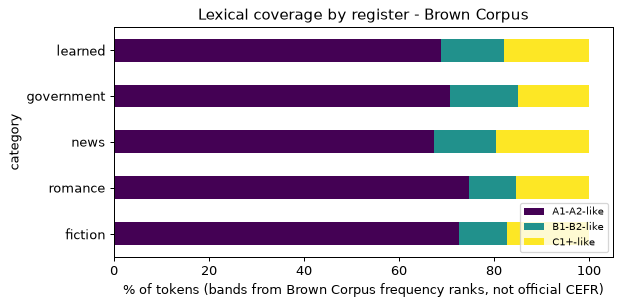

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.5))
profile_df[["A1-A2-like", "B1-B2-like", "C1+-like"]].plot.barh(stacked=True, ax=ax,
                                                               colormap="viridis")
ax.set_xlabel("% of tokens (bands from Brown Corpus frequency ranks, not official CEFR)")
ax.set_title("Lexical coverage by register - Brown Corpus")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
# The Agg backend (chosen for script-safety) does not render inline, so show the PNG bytes.
import io
from IPython.display import Image, display
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=90, bbox_inches="tight")
plt.close(fig)
display(Image(buffer.getvalue()))

**Interpretação (com cautela), com base na tabela acima:**

- `romance` e `fiction` têm a **maior parcela de tokens na faixa "A1–A2-like"** (~73–75%): narrativas usam muito vocabulário de alta frequência.
- `news` tem a **maior parcela "C1+-like"** (~20%) — provavelmente por nomes próprios, lugares e termos de atualidade (o script converte tudo para minúsculas, então nomes próprios entram como "palavras").
- `government` tem o **menor TTR** entre os registros de tamanho parecido, sinal de vocabulário repetitivo/formulaico, mas a maior fatia "B1–B2-like".
- Em `learned`, a palavra mais frequente é **"af"** — um artefato de notação técnica do corpus, não uma palavra do inglês. Isso mostra por que uma CLI de NLP precisa de opções de limpeza (ex.: `--min-length`, lista de exclusão).
- As faixas são **derivadas do próprio Brown Corpus** (inglês americano escrito de 1961); não refletem listas pedagógicas oficiais nem o inglês contemporâneo, e uma diferença de poucos pontos percentuais não indica, sozinha, dificuldade de leitura.
- O mesmo script poderia receber textos de alunos ou de livros didáticos — a interface permaneceria a mesma.

In [23]:
# CSV output is ready for spreadsheets; invalid input is rejected with exit code 2.
_ = run_vocab("--corpus", "romance", "--top", "5", "--output-format", "csv")
print()
_ = run_vocab("--corpus", "tweets")
print()
_ = run_vocab("--min-freq", "0")

$ python vocab_cli.py --corpus romance --top 5 --output-format csv   -> exit 0
word,freq,band
said,331,A1-A2-like
would,247,A1-A2-like
could,195,A1-A2-like
like,189,A1-A2-like
one,182,A1-A2-like



$ python vocab_cli.py --corpus tweets   -> exit 2
usage: vocab_cli [-h] [--corpus CATEGORY [CATEGORY ...]] [--language LANG]
                 [--min-freq MIN_FREQ] [--top TOP]
                 [--output-format {table,json,csv}]
vocab_cli: error: argument --corpus: invalid choice: 'tweets' (choose from 'adventure', 'belles_lettres', 'editorial', 'fiction', 'government', 'hobbies', 'humor', 'learned', 'lore', 'mystery', 'news', 'religion', 'reviews', 'romance', 'science_fiction')



$ python vocab_cli.py --min-freq 0   -> exit 2
usage: vocab_cli [-h] [--corpus CATEGORY [CATEGORY ...]] [--language LANG]
                 [--min-freq MIN_FREQ] [--top TOP]
                 [--output-format {table,json,csv}]
vocab_cli: error: --min-freq and --top must be >= 1


## 5. Boas práticas e integração

### 5.1 De notebook para script com `nbconvert`

`jupyter nbconvert --to script notebook.ipynb` extrai as células de código para um `.py`. O resultado é um **ponto de partida**, não um script pronto: é preciso remover células exploratórias, mover parâmetros fixos para argumentos do `argparse` e envolver tudo em `main(argv=None)`. A célula abaixo converte um notebook real deste repositório para mostrar o formato gerado.

In [24]:
import shutil

nb_candidates = sorted(Path(".").glob("2026-1*_*.ipynb"))
source_nb = next(p for p in nb_candidates if "argparse" not in p.name)
target = WORKDIR / "converted"
cmd = [PY, "-m", "jupyter", "nbconvert", "--to", "script", str(source_nb),
       "--output-dir", str(target)]
res = subprocess.run(cmd, capture_output=True, text=True, timeout=120)
print(f"nbconvert exit code: {res.returncode} (source: {source_nb.name})")
script = next(target.glob("*.py"))
lines = script.read_text(encoding="utf-8").splitlines()
print(f"{script.name}: {len(lines)} lines; first 12 lines:\n")
print("\n".join(lines[:12]))

nbconvert exit code: 0 (source: 2026-10-18_string_manipulation_regex.ipynb)
2026-10-18_string_manipulation_regex.py: 949 lines; first 12 lines:

#!/usr/bin/env python
# coding: utf-8

# # 🔤 Dia 5 — Manipulação de Strings & Regex para Data Science / PLN
# 
# **Autor:** Gutemberg Rapôso · **Data:** 2026-10-18 · **Fase 1 — Python Basics (Dia 5/28)**
# 
# > Parte de uma jornada estruturada de 210 dias: *Junior → Senior Data Scientist | Aberto a Oportunidades Remotas*.
# 
# ## 🎯 Objetivos de Aprendizagem
# 
# Ao final deste notebook, você será capaz de:


### 5.2 `argparse` + `logging`

Padrão recomendado (visto no Dia 16 e usado no `ds_pipeline.py`):

- **`stdout`** só para o *resultado* (JSON/CSV) — assim ele pode ser redirecionado com `>` ou lido por outro programa;
- **`stderr`** para logs e diagnósticos;
- `-v`/`-vv` com `action="count"` para controlar o nível, e `--log-file` opcional.

In [25]:
import logging


def configure_logging(argv: list[str]) -> argparse.Namespace:
    """Map -v/-q/--log-file CLI options to a configured root logger."""
    p = argparse.ArgumentParser(prog="logdemo")
    p.add_argument("-v", "--verbose", action="count", default=0)
    p.add_argument("-q", "--quiet", action="store_true")
    p.add_argument("--log-file", type=Path)
    args = p.parse_args(argv)
    level = logging.ERROR if args.quiet else [logging.WARNING, logging.INFO,
                                              logging.DEBUG][min(args.verbose, 2)]
    handlers = [logging.StreamHandler(sys.stdout)]  # stdout here only so the notebook shows it
    if args.log_file:
        handlers.append(logging.FileHandler(args.log_file, mode="w"))
    logging.basicConfig(level=level, handlers=handlers, force=True,
                        format="%(levelname)-7s %(message)s")
    return args


for argv in (["-q"], [], ["-vv", "--log-file", str(WORKDIR / "run.log")]):
    configure_logging(argv)
    df = sns.load_dataset("titanic")
    print(f"--- argv={argv} -> level {logging.getLevelName(logging.getLogger().level)}")
    logging.debug("dtypes: %s", dict(df.dtypes.astype(str).value_counts()))
    logging.info("loaded titanic with %d rows", len(df))
    logging.warning("%d missing ages", df["age"].isna().sum())
logging.getLogger().handlers.clear()
print("log file lines:", len((WORKDIR / "run.log").read_text().splitlines()))

--- argv=['-q'] -> level ERROR
--- argv=[] -> level WARNING
WARNING 177 missing ages


--- argv=['-vv', '--log-file', '/tmp/day20_cli_87rv5go8/run.log'] -> level DEBUG
DEBUG   dtypes: {'object': 5, 'int64': 4, 'float64': 2, 'category': 2, 'bool': 2}


INFO    loaded titanic with 891 rows


WARNING 177 missing ages


log file lines: 3


### 5.3 Testando CLIs com `pytest`

Como `main(argv)` retorna um código de saída, testamos sem *mock* de `sys.argv`. O *fixture* `capsys` captura `stdout`/`stderr`, e `pytest.raises(SystemExit)` verifica erros de uso. Um teste de "fumaça" com `subprocess` garante que o script também funciona como processo.

In [26]:
TEST_SRC = textwrap.dedent('''
    import json
    import subprocess
    import sys

    import pytest

    import ds_pipeline


    @pytest.fixture
    def model_path(tmp_path):
        path = tmp_path / "iris.joblib"
        assert ds_pipeline.main(["train", "--dataset", "iris", "--output", str(path)]) == 0
        return path


    def test_train_reports_json(tmp_path, capsys):
        out = tmp_path / "m.joblib"
        assert ds_pipeline.main(["train", "--dataset", "wine", "--model", "knn",
                                 "--output", str(out)]) == 0
        payload = json.loads(capsys.readouterr().out)
        assert payload["status"] == "trained" and out.exists()


    def test_evaluate_metrics_in_range(model_path, capsys):
        capsys.readouterr()
        assert ds_pipeline.main(["evaluate", "--model-path", str(model_path)]) == 0
        metrics = json.loads(capsys.readouterr().out)
        assert 0.0 <= metrics["accuracy"] <= 1.0 and metrics["n_test"] == 38


    @pytest.mark.parametrize("argv", [
        ["train", "--dataset", "mnist", "--output", "x"],
        ["train", "--dataset", "iris"],
        ["unknown-command"],
    ])
    def test_usage_errors_exit_2(argv):
        with pytest.raises(SystemExit) as exc:
            ds_pipeline.main(argv)
        assert exc.value.code == 2


    def test_missing_model_returns_1(tmp_path):
        assert ds_pipeline.main(["evaluate", "--model-path", str(tmp_path / "no.joblib")]) == 1


    def test_cli_smoke_subprocess():
        res = subprocess.run([sys.executable, "ds_pipeline.py", "--help"],
                             capture_output=True, text=True)
        assert res.returncode == 0 and "train" in res.stdout
''')
(WORKDIR / "test_ds_pipeline.py").write_text(TEST_SRC)
res = subprocess.run([PY, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_ds_pipeline.py"],
                     capture_output=True, text=True, cwd=WORKDIR, timeout=300)
print(res.stdout[-600:])
assert res.returncode == 0

.......                                                                  [100%]
7 passed in 2.18s



### 5.4 Empacotando a CLI como *entry point*

No Dia 18 vimos `pyproject.toml`. Para que `ds-pipeline train ...` funcione como comando instalado, basta apontar `[project.scripts]` para a função `main`:

```toml
[project.scripts]
ds-pipeline = "dskit.cli.pipeline:main"
vocab-profile = "nlp_edu.cli.vocab:main"
```

Após `pip install -e .`, o pip cria executáveis que chamam `sys.exit(main())` — por isso `main` deve **retornar um código de saída**. A célula abaixo valida esse trecho com `tomllib` (sem instalar nada).

In [27]:
import tomllib

PYPROJECT = """
[project]
name = "ds-cli-tools"
version = "0.1.0"
requires-python = ">=3.10"
dependencies = ["scikit-learn", "pandas", "joblib", "nltk"]

[project.scripts]
ds-pipeline = "dskit.cli.pipeline:main"
vocab-profile = "nlp_edu.cli.vocab:main"
"""
config = tomllib.loads(PYPROJECT)
for command, target in config["project"]["scripts"].items():
    module, func = target.split(":")
    print(f"{command:<14} -> import {module}; sys.exit({func}())")

ds-pipeline    -> import dskit.cli.pipeline; sys.exit(main())
vocab-profile  -> import nlp_edu.cli.vocab; sys.exit(main())


### Checklist de uma boa CLI para Data Science

| Prática | Por quê |
|---|---|
| `main(argv=None)` retornando código de saída | testável sem `subprocess`; compatível com *entry points* |
| `type=`, `choices=` e validadores próprios | erros detectados antes de gastar minutos carregando dados |
| `parser.error()` para validação pós-parse | mensagens e código `2` consistentes |
| Resultado em `stdout`, logs em `stderr` | permite `> results.json` e encadeamento com `|` |
| Saídas JSON/CSV | fáceis de orquestrar (Airflow, Makefile, notebooks) |
| Semente e parâmetros salvos com o artefato | reprodutibilidade de `evaluate`/`predict` |
| Testes com `pytest` (`capsys`, `SystemExit`) | evita regressões silenciosas na interface |

## Resumo

- `argparse` converte texto da linha de comando em parâmetros **tipados e validados**, com ajuda automática.
- Subcomandos + `set_defaults(func=...)` organizam ferramentas com várias ações (`train`/`evaluate`/`predict`).
- Uma CLI determinística com saída JSON transforma experimentos em blocos orquestráveis — fizemos um *grid* 3×3 em sklearn.
- A mesma ideia serve à linguística aplicada: `vocab_cli.py` gera perfis lexicais por registro com faixas de frequência **inspiradas** no CEFR (não oficiais).

**Próximos passos (Dia 21):** consolidar os fundamentos de Python com um mini-projeto integrando arquivos, SQL, logging e CLI. Uma alternativa a explorar depois é o **Typer/Click**, que constrói CLIs a partir de *type hints*.

In [28]:
# Clean up the temporary working directory created at the start of the notebook.
n_files = sum(1 for p in WORKDIR.rglob("*") if p.is_file())
shutil.rmtree(WORKDIR)
print(f"removed temporary folder with {n_files} files; exists now: {WORKDIR.exists()}")

removed temporary folder with 20 files; exists now: False
